# **LOAN ANALYSIS**

# OBJECTIVE :



Using known previous loan outcomes from the Berka database, we study what information, available before a loan is granted, tells us whether a client will repay it or default.


---


**Data:**

The data comes from the Berka dataset (LOANS table), linked to other tables to extract the required Features.

we have **279** loans:

203 loans are good (Finished, paid)

76 loans are bad (Finished, not paid / Running, in debt)


---



**Features:**

1. Region : Region of the account owner.
2. Salary_Flag : 1 if the account receives regular salary-type transfers otherwise 0.
3. Account_Age : Months from account opening to the loan date.
4. Loan_Duration : Number of months of the loan.
5. Capacity : Average monthly net (money in minus money out) divided by the monthly loan payment.
6. R : Standard deviation of the monthly net divided by the average monthly income (for standardization).




We are going to extract the required features. Then analyze the data by looking for patterns through visualizations and by applying the logistic regression method.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from scipy.stats import chi2
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix
import warnings
warnings.simplefilter("ignore")

# DATA EXTRACTION :

In [2]:
Data_url="https://raw.githubusercontent.com/aliabedalkereem-byte/Data-Analytics-Portfolio/refs/heads/main/1.Berka_Database_Exploring/Data/"

LOANS=pd.read_csv(Data_url + "LOANS.csv")
TRANS_TABLE=pd.read_csv(Data_url + "TRANS_TABLE.csv")
ACCOUNTS=pd.read_csv(Data_url + "ACCOUNTS.csv")
INCOME=pd.read_csv(Data_url + "ACCOUNTS_INCOME.csv")


In [3]:
#extract loan information
LOANS1=LOANS.loc[(LOANS["Loan"]== "YES") & ((LOANS["Loan_Status"]=="A")|(LOANS["Loan_Status"]=="B")|(LOANS["Loan_Status"]=="D")),:]
LOANS1["TARGET"]=LOANS1["Loan_Status"].map({"A":0,"B":1,"D":1})
LOANS1["Loan_Payments"] = LOANS1["Loan_Payments"].astype(str).str.replace("$", "", regex=False)
LOANS1["Loan_Payments"] = LOANS1["Loan_Payments"].str.replace(",", "", regex=False)
LOANS1["Loan_Payments"] = pd.to_numeric(LOANS1["Loan_Payments"], errors="coerce")

#extract region and income source information
region=pd.merge(LOANS1,ACCOUNTS,left_on="Account_ID",right_on="Account_ID",how="inner")[["Account_ID","Region"]]
salary=pd.merge(LOANS1,INCOME,left_on="Account_ID",right_on="Account_ID",how="inner")
salary["Salary_Flag"]=np.where(salary["Base_Salary"]!="$0.00",1,0)
salary=salary[["Account_ID","Salary_Flag"]]

#extract account historical information
trans=pd.merge(LOANS1,TRANS_TABLE,left_on="Account_ID",right_on="account_id",how="inner")
trans["Loan_Date"]= pd.to_datetime(trans["Loan_Date"])
trans["date"]= pd.to_datetime(trans["date"])
trans1=trans[trans["date"]<trans["Loan_Date"]]
trans1["Account_Age"] = (trans1.groupby("Account_ID")["date"].transform(lambda x: (x.max().to_period('M') - x.min().to_period('M')).n + 1 ))

trans1["year"]=trans1["date"].dt.year
trans1["month"]=trans1["date"].dt.month
trans1["IN"] = np.where(trans1["type"] == "PRIJEM", trans1["amount"], 0)
trans1["OUT"] = np.where(trans1["type"].isin(["VYDAJ", "VYBER"]),trans1["amount"], 0)
trans1["net"]=trans1["IN"]-trans1["OUT"]

trans2 = trans1.groupby(["Account_ID", "year", "month"], as_index=False).agg({
    "Account_Age": "first",
    "IN":"sum",
    "net":"sum"})
trans2=trans2.sort_values(by=["Account_ID","year","month"],ascending=True)
trans2[:]

trans3 = trans2.groupby(["Account_ID"], as_index=False).agg(
    Account_Age=("Account_Age", "first"),
    IN_sum=("IN","sum"),
    net_sum=("net","sum"),
    net_std=("net","std"))
trans3[:]

##### combine all informations togather
DATA=pd.merge(LOANS1,region,left_on="Account_ID",right_on="Account_ID",how="inner")
DATA=pd.merge(DATA,salary,left_on="Account_ID",right_on="Account_ID",how="inner")
DATA=DATA.drop(columns=["Loan","Loan_Date","loan_Amount","Loan_Status"])
DATA=pd.merge(DATA,trans3,left_on="Account_ID",right_on="Account_ID",how="inner")
DATA["capacity"]=(DATA["net_sum"]/DATA["Account_Age"])/DATA["Loan_Payments"]
DATA["R"]=DATA["net_std"]/(DATA["IN_sum"]/DATA["Account_Age"])
features=DATA.drop(columns=["Loan_Payments","IN_sum","net_std","net_sum"])

features[:]

,Account_ID,Loan_Duration,TARGET,Region,Salary_Flag,Account_Age,capacity,R
0,2,24.0,0,Prague,1,11,0.750344,0.467731
1,426,60.0,1,south Moravia,0,9,1.853924,0.346452
2,718,12.0,0,Prague,0,18,0.513395,0.535405
3,1603,12.0,0,west Bohemia,0,10,0.373989,0.869082
4,2106,12.0,0,Prague,0,8,0.247045,0.725458
...,...,...,...,...,...,...,...,...
274,9750,48.0,1,north Moravia,0,10,0.837963,1.118982
275,7857,12.0,0,north Bohemia,1,18,0.385757,0.520543
276,10789,12.0,0,north Moravia,0,16,1.251704,0.535753
277,11135,36.0,0,north Moravia,0,5,1.800158,0.572142


# EXPLORATION :

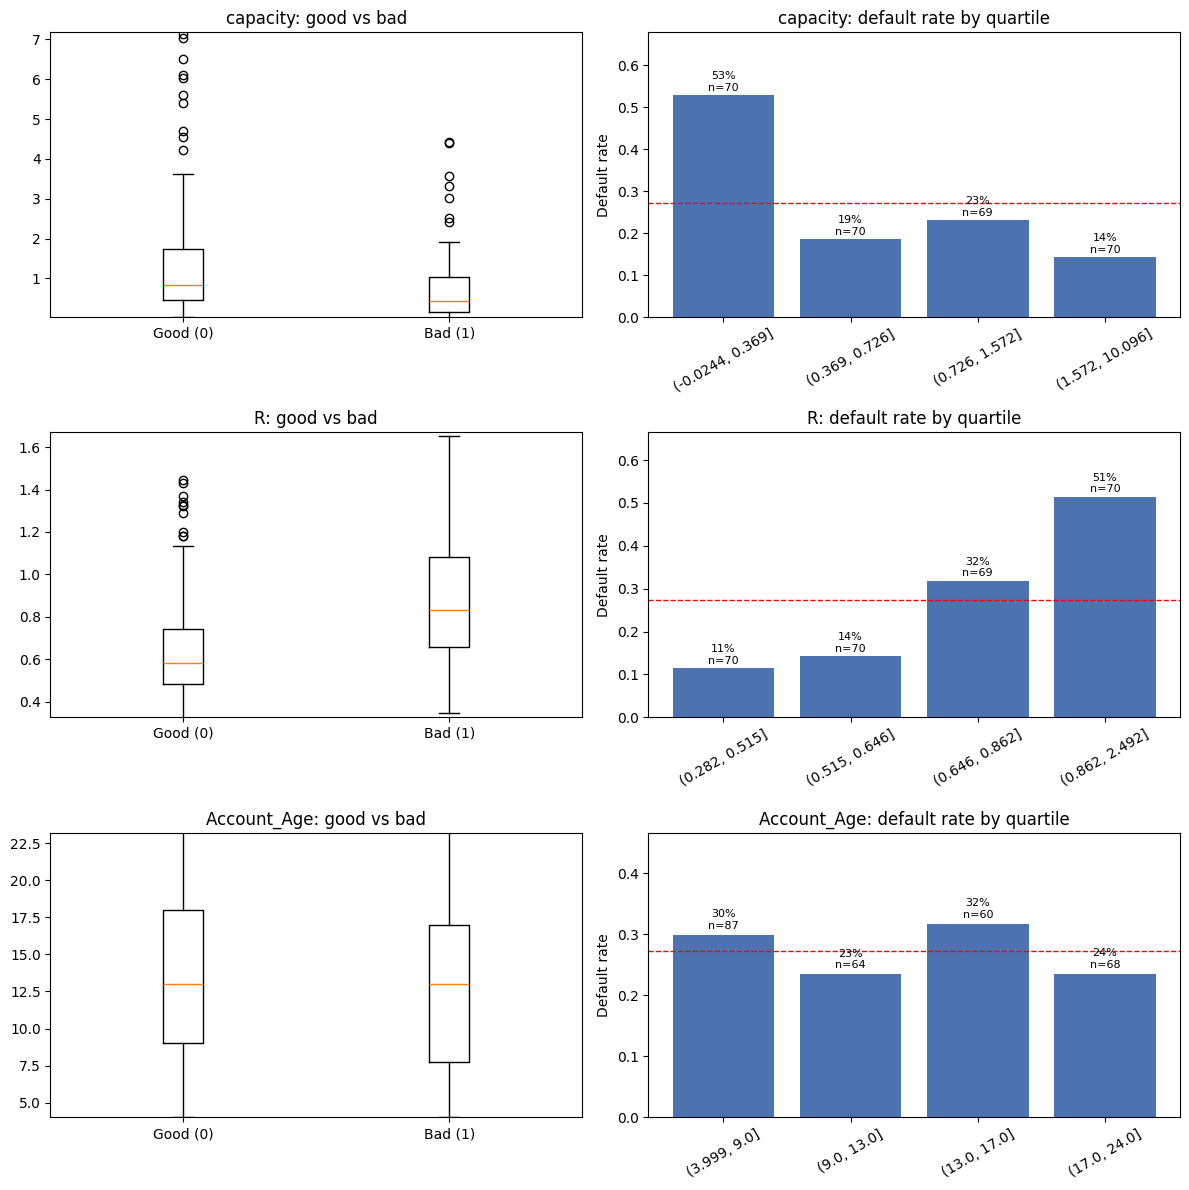

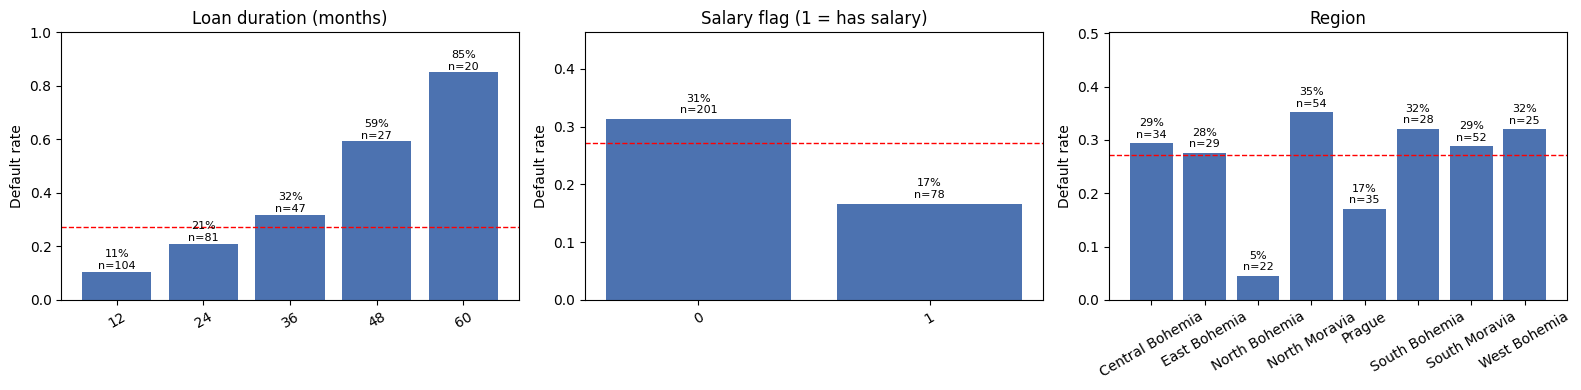

In [6]:
df = features.copy()

# overall default rate (~27%)
base = df["TARGET"].mean()

num_cols = ["capacity", "R", "Account_Age"]

def rate_bars(ax, groups, title):
    """Default rate per group, with sample size on each bar."""
    t = df.groupby(groups, observed=True)["TARGET"].agg(rate="mean", n="count")
    ax.bar(t.index.astype(str), t["rate"], color="#4C72B0")
    ax.axhline(base, ls="--", c="red", lw=1)    # overall rate for reference
    for i, (r, n) in enumerate(zip(t["rate"], t["n"])):
        ax.text(i, r + 0.01, f"{r:.0%}\nn={n}", ha="center", fontsize=8)
    ax.set_ylim(0, min(1, t["rate"].max() + 0.15))
    ax.set_title(title)
    ax.set_ylabel("Default rate")
    ax.tick_params(axis="x", rotation=30)

# ---------- 1) Numeric features: good vs bad + default rate by quartile ----------
fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 4 * len(num_cols)))

for c, (ax_box, ax_bar) in zip(num_cols, axes):
    good = df.loc[df["TARGET"] == 0, c]
    bad = df.loc[df["TARGET"] == 1, c]

    ax_box.boxplot([good, bad])
    ax_box.set_xticks([1, 2], ["Good (0)", "Bad (1)"])
    ax_box.set_ylim(df[c].quantile(0.01), df[c].quantile(0.99))   # zoom: ignore extreme outliers
    ax_box.set_title(f"{c}: good vs bad")

    rate_bars(ax_bar, pd.qcut(df[c], 4, duplicates="drop"), f"{c}: default rate by quartile")


plt.tight_layout()
plt.show()

# ---------- 2) Categorical / discrete features: default rate per group ----------
fig, axes = plt.subplots(1,3,figsize=(16, 4))
rate_bars(axes[0], df["Loan_Duration"].astype(int), "Loan duration (months)")
rate_bars(axes[1], df["Salary_Flag"], "Salary flag (1 = has salary)")
rate_bars(axes[2], df["Region"].str.title(), "Region")

plt.tight_layout()
plt.show()

# MODELLING :

In [7]:
# ============================================================
# DATA
# ============================================================

y = features["TARGET"]
X = features[["Loan_Duration", "Account_Age", "capacity", "R", "Salary_Flag", "Region"]]

X = pd.get_dummies(X).astype(float)                    # every region becomes a 0/1 column
X = X.drop(columns="Region_east Bohemia")              # East Bohemia = reference group
continuous = ["Loan_Duration", "Account_Age", "capacity", "R"]

cv = StratifiedKFold(5, shuffle=True, random_state=42)   # 5-fold cross-validation

print(f"Sample: n = {len(y)} loans, {y.sum()} bad ({y.mean():.1%})")

# ============================================================
# ONE FUNCTION = ONE STAGE
# ============================================================
def run_stage(cols, name):
    # (a) Logistic regression on all loans: coefficients, odds ratios, 95% CI, p-values
    Xs = X[cols].copy()
    c = [v for v in continuous if v in cols]
    Xs[c] = (Xs[c] - Xs[c].mean()) / Xs[c].std()          # continuous variables: effect per 1 standard deviation
    fit = sm.Logit(y, sm.add_constant(Xs)).fit(disp=0)
    ci = fit.conf_int()
    table = pd.DataFrame({"Coef": fit.params, "Odds ratio": np.exp(fit.params),
                          "CI low": np.exp(ci[0]), "CI high": np.exp(ci[1]),
                          "p-value": fit.pvalues}).drop("const")
    print(f"\n===== {name} =====")
    print(table.round(3).to_string())

    # (b) Prediction quality on loans the model has not seen (5-fold cross-validation)
    model = make_pipeline(StandardScaler(), LogisticRegression())
    cvr = cross_validate(model, X[cols], y, cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    result = {"Model": name, "Parameters": len(cols),
              "Accuracy": cvr["test_accuracy"].mean(), "F1": cvr["test_f1"].mean(),
              "ROC AUC": cvr["test_roc_auc"].mean(), "AIC": fit.aic, "BIC": fit.bic}
    return fit, table, result

# ============================================================
# STAGE 1: all features
# ============================================================
fit1, table1, res1 = run_stage(list(X.columns), "Stage 1: all features")

# ============================================================
# STAGE 2: only features with a significant effect (p < 0.05)
# ============================================================
kept = table1.index[table1["p-value"] < 0.05].tolist()
print("\nKept for Stage 2:", kept)
fit2, table2, res2 = run_stage(kept, "Stage 2: significant features")

# ============================================================
# COMPARISON
# ============================================================
print("\n===== Model comparison (5-fold cross-validation) =====")
print(pd.DataFrame([res1, res2]).round(3).to_string(index=False))
print("Baseline accuracy (always predict 'good'):", round(1 - y.mean(), 3))

# Likelihood-ratio test: do the removed variables add anything together?
lr = 2 * (fit1.llf - fit2.llf)
df = int(fit1.df_model - fit2.df_model)
print(f"\nLikelihood-ratio test (Stage 1 vs Stage 2): chi2 = {lr:.2f}, df = {df}, p = {chi2.sf(lr, df):.3f}")

# Confusion matrix of the final model (cross-validated predictions)
pred = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression()), X[kept], y, cv=cv)
print("\nConfusion matrix, final model (rows = actual, columns = predicted):")
print(pd.DataFrame(confusion_matrix(y, pred), index=["actual good", "actual bad"],
                   columns=["predicted good", "predicted bad"]))

Sample: n = 279 loans, 76 bad (27.2%)

===== Stage 1: all features =====
                         Coef  Odds ratio  CI low  CI high  p-value
Loan_Duration           1.053       2.866   2.035    4.037    0.000
Account_Age            -0.213       0.808   0.524    1.246    0.335
capacity               -0.826       0.438   0.222    0.865    0.017
R                       0.840       2.316   1.550    3.462    0.000
Salary_Flag            -0.228       0.796   0.342    1.854    0.597
Region_Prague          -0.161       0.852   0.199    3.636    0.828
Region_central Bohemia  0.582       1.790   0.443    7.227    0.414
Region_north Bohemia   -2.719       0.066   0.005    0.916    0.043
Region_north Moravia    0.592       1.808   0.496    6.591    0.369
Region_south Bohemia    0.798       2.221   0.514    9.588    0.285
Region_south Moravia   -0.060       0.941   0.246    3.601    0.930
Region_west Bohemia    -0.135       0.874   0.203    3.762    0.856

Kept for Stage 2: ['Loan_Duration', 'capac